# Comparaison statistique : 

## Western United 4–2 Auckland FC 

Ce notebook compare les deux équipes lors du match `2015213`, d'abord sur les statistiques générales, puis sur les actions associées à la zone 14. Il complète le notebook 02_analyse_zone14 en appliquant les mêmes fonctions à chacun des deux clubs.

Les résultats sont présentés uniquement dans des tableaux. Les explications portent sur les choix méthodologiques et le code Python, l'interprétation du résultat sportif est réservée à la synthèse.

## 1. Importation des bibliothèques et des fonctions

Comme dans le notebook 02, nous importons Pandas et les fonctions de `src/fonctions_zone14.py`.

In [62]:
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

if Path('src').exists():
    sys.path.append('src')
else:
    sys.path.append('../src')

from fonctions_zone14 import (
    passes_depuis_zone14, 
    frappes_depuis_zone14,
    passes_vers_zone14, 
    courses_vers_zone14, 
    courses_depuis_zone14,
    tracer_terrain, 
    carte_actions, 
    bilan_match
)

## 2. Chargement des données du match

Le fichier Parquet rassemble les événements, tandis que le fichier JSON contient notamment les équipes et les bornes temporelles des mi-temps. 

In [63]:
import s3fs
import json

fs = s3fs.S3FileSystem(
    endpoint_url='https://minio.lab.sspcloud.fr',
    client_kwargs={'region_name': 'us-east-1'}
)

id_match = 2015213
adresse = f's3://lfaivre/diffusion/{id_match}'

evenements = pd.read_parquet(adresse + '_dynamic_events.parquet', filesystem=fs)
with fs.open(adresse + '_match.json', 'r') as fichier:
    infos = json.load(fichier)

id_western = int(infos['home_team']['id'])
id_auckland = int(infos['away_team']['id'])

# Vérification de l'identifiant connu d'Auckland.
assert id_auckland == 4177, 'Vérifier les équipes du match chargé.'

print('Match :', infos['home_team']['name'], '-', infos['away_team']['name'])
print('Identifiants :', id_western, 'et', id_auckland)
print('Nombre d’événements :', len(evenements))

Match : Western United - Auckland FC
Identifiants : 1803 et 4177
Nombre d’événements : 4613


## 3. Statistiques générales

Nous filtrons les événements `player_possession` avec `.loc[]`, puis les passes et les tirs grâce à `end_type`. `len()` donne le nombre d'événements.



In [64]:
equipes = {
    'Western United': id_western,
    'Auckland FC': id_auckland
}

#Sélection des possessions individuelles.
possessions = evenements.loc[evenements['event_type'] == 'player_possession'].copy()

scores = {'Western United': 4, 'Auckland FC': 2}
passes_match = {}
tirs_match = {}
lignes_stats = []

for nom, identifiant in equipes.items():
    equipe = possessions.loc[possessions['team_id'] == identifiant].copy()
    passes = equipe.loc[equipe['end_type'] == 'pass'].copy()
    tirs = equipe.loc[equipe['end_type'] == 'shot'].copy()
    passes_match[nom] = passes
    tirs_match[nom] = tirs

    nb_tirs = len(tirs)
    tirs_z14 = len(frappes_depuis_zone14(infos, evenements, identifiant))
    lignes_stats.append({
        'Equipe': nom,
        'Buts (score final)': scores[nom],
        'Passes identifiées': len(passes),
        'Tirs identifiés': nb_tirs,
        'Tirs depuis Z14': tirs_z14,
        'Part tirs depuis Z14 (%)': 100 * tirs_z14 / nb_tirs if nb_tirs else float('nan'),
        'Buts / tirs identifiés (%)': 100 * scores[nom] / nb_tirs if nb_tirs else float('nan')
    })

stats_generales = pd.DataFrame(lignes_stats).set_index('Equipe')
stats_generales.round(2)

,Buts (score final),Passes identifiées,Tirs identifiés,Tirs depuis Z14,Part tirs depuis Z14 (%),Buts / tirs identifiés (%)
Equipe,,,,,,
Western United,4,315,10,1,10.00,40.00
Auckland FC,2,421,12,2,16.67,16.67


## 4. Comparaison par mi-temps

Les champs `start_frame` et `end_frame` du JSON délimitent chaque mi-temps. Nous attribuons les événements à leur période selon `frame_start`. Les filtres avec `>=`, `<` et `<=` jouent le même rôle que les sélections conditionnelles du notebook 02.

Les tableaux sont créés par des boucles `for` et une liste de dictionnaires.

In [65]:
lignes_mi_temps = []
periodes = infos['match_periods'][:2]

for numero, periode in enumerate(periodes, start=1):
    debut = int(periode['start_frame'])
    fin = int(periode['end_frame'])
    for nom, identifiant in equipes.items():
        actions = possessions.loc[
            (possessions['team_id'] == identifiant)
            & (possessions['frame_start'] >= debut)
            & (possessions['frame_start'] <= fin)
        ].copy()
        lignes_mi_temps.append({
            'Mi-temps': numero,
            'Equipe': nom,
            'Passes': (actions['end_type'] == 'pass').sum(),
            'Tirs': (actions['end_type'] == 'shot').sum()
        })

stats_mi_temps = pd.DataFrame(lignes_mi_temps)
stats_mi_temps

,Mi-temps,Equipe,Passes,Tirs
0,1,Western United,203,4
1,1,Auckland FC,225,2
2,2,Western United,112,6
3,2,Auckland FC,196,10


## 5. Bilan complet de la zone 14 sur l'ensemble du match

Nous appliquons `bilan_match()` aux deux équipes. Les fonctions du script utilisent la même définition géographique de la zone 14 et les mêmes règles de sélection des passes, tirs et courses. Les résultats obtenus sont réunis dans un DataFrame à l'aide d'une liste de dictionnaires.

Les valeurs EPV sont calculées sur les actions retenues avec `.mean()` ou `.sum()`. L'EPV des passes mesure une variation de valeur offensive, tandis que `possession_epv_for_end` mesure la valeur estimée en fin de possession ; il ne s'agit pas de xG. Toutes les statistiques de zone 14 figurent dans un seul tableau, sans colonne de différence.


In [66]:
lignes_bilan = []
for nom, identifiant in equipes.items():
    resultat = bilan_match(infos, evenements, identifiant)
    passes_z14 = passes_depuis_zone14(infos, evenements, identifiant)
    tirs_z14 = frappes_depuis_zone14(infos, evenements, identifiant)

    lignes_bilan.append({
        'Equipe': nom,
        'Passes totales': resultat['Passes totales'],
        'Passes depuis Z14': resultat['Passes depuis Z14'],
        'Part passes depuis Z14 (%)': resultat['Part passes depuis Z14 (%)'],
        'EPV moyen passes Z14': resultat['EPV moyen passes Z14'],
        'EPV cumulé passes Z14': passes_z14['pass_epv_delta_for'].sum(min_count=1),
        'Passes vers Z14 (estimées)': resultat['Passes vers Z14 (estimées)'],
        'Frappes totales': resultat['Frappes totales'],
        'Frappes depuis Z14': resultat['Frappes depuis Z14'],
        'Part frappes depuis Z14 (%)': 100 * len(tirs_z14) / resultat['Frappes totales'] if resultat['Frappes totales'] else float('nan'),
        'EPV moyen fin tirs Z14': tirs_z14['possession_epv_for_end'].mean(),
        'Courses vers Z14': resultat['Courses vers Z14'],
        'Courses depuis Z14': resultat['Courses depuis Z14']
    })

bilan_equipes = pd.DataFrame(lignes_bilan).set_index('Equipe')
bilan_equipes.round(3)


,Passes totales,Passes depuis Z14,Part passes depuis Z14 (%),EPV moyen passes Z14,EPV cumulé passes Z14,Passes vers Z14 (estimées),Frappes totales,Frappes depuis Z14,Part frappes depuis Z14 (%),EPV moyen fin tirs Z14,Courses vers Z14,Courses depuis Z14
Equipe,,,,,,,,,,,,
Western United,315,16,5.079,0.012,0.170,10,10,1,10.000,0.072,25,6
Auckland FC,421,6,1.425,-0.001,-0.006,4,12,2,16.667,0.076,22,15


## 6. Premières et dernières dix minutes de chaque mi-temps

Nous ajoutons quatre fenêtres : début et fin de la première mi-temps, début et fin de la seconde. SkillCorner enregistre 10 frames par seconde. Dix minutes correspondent donc à `10 * 60 * 10`, soit 6 000 frames.

Les bornes proviennent des `start_frame` et `end_frame` de chaque mi-temps. Le créneau « fin » correspond aux dix dernières minutes effectivement enregistrées avant la fin de la période, il peut donc inclure du temps additionnel. 

Pour les passes et les tirs, on retient le `frame_start` de la possession pour décider si l'action est dans la période ou non. Pour les courses, le `frame_start` de la course. Pour les passes estimées vers la zone 14, on retient la frame de fin de possession du passeur (`frame_end`), afin de dater l'action qui déclenche l'estimation. 

In [67]:
#Création des quatre fenêtres à partir des informations du match.
frames_dix_minutes = 10 * 60 * 10
fenetres = []

for numero, periode in enumerate(infos['match_periods'][:2], start=1):
    debut = int(periode['start_frame'])
    fin = int(periode['end_frame'])
    fenetres.append({
        'Période': 'Mi-temps ' + str(numero) + ' - 10 premières minutes',
        'Début': debut,
        'Fin': debut + frames_dix_minutes
    })
    fenetres.append({
        'Période': 'Mi-temps ' + str(numero) + ' - 10 dernières minutes',
        'Début': fin - frames_dix_minutes,
        'Fin': fin
    })

pd.DataFrame(fenetres)

,Période,Début,Fin
0,Mi-temps 1 - 10 premières minutes,2210,8210
1,Mi-temps 1 - 10 dernières minutes,25040,31040
2,Mi-temps 2 - 10 premières minutes,40280,46280
3,Mi-temps 2 - 10 dernières minutes,65350,71350


### Statistiques générales dans les quatre fenêtres

Une double boucle `for` parcourt les fenêtres et les équipes. Les filtres Pandas repèrent les événements dont le début appartient au créneau. Les tableaux sont créés avec `pd.DataFrame()` sans transposition ni tableau croisé.

Nous affichons ici seulement les passes et les tirs identifiés. Les statistiques détaillées de la zone 14 sont regroupées dans un tableau complet plus bas.


In [68]:
lignes_courtes = []
for fenetre in fenetres:
    debut = fenetre['Début']
    fin = fenetre['Fin']
    for nom, identifiant in equipes.items():
        actions = possessions.loc[
            (possessions['team_id'] == identifiant)
            & (possessions['frame_start'] >= debut)
            & (possessions['frame_start'] < fin)
        ].copy()
        passes = actions.loc[actions['end_type'] == 'pass'].copy()
        tirs = actions.loc[actions['end_type'] == 'shot'].copy()
        lignes_courtes.append({
            'Période': fenetre['Période'],
            'Equipe': nom,
            'Passes': len(passes),
            'Tirs': len(tirs)
        })

stats_courtes = pd.DataFrame(lignes_courtes)
stats_courtes


,Période,Equipe,Passes,Tirs
0,Mi-temps 1 - 10 premières minutes,Western United,63,0
1,Mi-temps 1 - 10 premières minutes,Auckland FC,63,0
2,Mi-temps 1 - 10 dernières minutes,Western United,37,0
3,Mi-temps 1 - 10 dernières minutes,Auckland FC,31,0
4,Mi-temps 2 - 10 premières minutes,Western United,26,2
5,Mi-temps 2 - 10 premières minutes,Auckland FC,54,2
6,Mi-temps 2 - 10 dernières minutes,Western United,22,3
7,Mi-temps 2 - 10 dernières minutes,Auckland FC,25,1


### Tableau complet de la zone 14 dans les quatre fenêtres

Les cinq fonctions de sélection sont réutilisées pour les deux équipes. Nous conservons leurs DataFrames complets, puis nous comptons les actions à l'intérieur des bornes temporelles de chaque fenêtre. Pour une passe estimée entrante, nous datons l'action au moment de la passe (`frame_end`), les autres événements sont datés par `frame_start`.




In [69]:
actions_zone14 = {}
for nom, identifiant in equipes.items():
    actions_zone14[nom] = {
        'Passes depuis Z14': passes_depuis_zone14(infos, evenements, identifiant),
        'Tirs depuis Z14': frappes_depuis_zone14(infos, evenements, identifiant),
        'Passes estimées vers Z14': passes_vers_zone14(infos, evenements, identifiant),
        'Courses vers Z14': courses_vers_zone14(infos, evenements, identifiant),
        'Courses depuis Z14': courses_depuis_zone14(infos, evenements, identifiant)
    }

lignes_zone14_courtes = []
for fenetre in fenetres:
    debut = fenetre['Début']
    fin = fenetre['Fin']
    for nom in equipes:
        actions = actions_zone14[nom]
        passes_z14 = actions['Passes depuis Z14'].loc[
            (actions['Passes depuis Z14']['frame_start'] >= debut)
            & (actions['Passes depuis Z14']['frame_start'] < fin)
        ]
        tirs_z14 = actions['Tirs depuis Z14'].loc[
            (actions['Tirs depuis Z14']['frame_start'] >= debut)
            & (actions['Tirs depuis Z14']['frame_start'] < fin)
        ]
        passes_vers = actions['Passes estimées vers Z14'].loc[
            (actions['Passes estimées vers Z14']['frame_end'] >= debut)
            & (actions['Passes estimées vers Z14']['frame_end'] < fin)
        ]
        courses_vers = actions['Courses vers Z14'].loc[
            (actions['Courses vers Z14']['frame_start'] >= debut)
            & (actions['Courses vers Z14']['frame_start'] < fin)
        ]
        courses_depuis = actions['Courses depuis Z14'].loc[
            (actions['Courses depuis Z14']['frame_start'] >= debut)
            & (actions['Courses depuis Z14']['frame_start'] < fin)
        ]
        generales = stats_courtes.loc[
            (stats_courtes['Période'] == fenetre['Période'])
            & (stats_courtes['Equipe'] == nom)
        ].iloc[0]
        nb_passes = generales['Passes']
        nb_tirs = generales['Tirs']

        lignes_zone14_courtes.append({
            'Période': fenetre['Période'],
            'Equipe': nom,
            'Passes totales': nb_passes,
            'Passes depuis Z14': len(passes_z14),
            'Passes vers Z14 (estimées)': len(passes_vers),
            'Frappes totales': nb_tirs,
            'Frappes depuis Z14': len(tirs_z14),
            'Courses vers Z14': len(courses_vers),
            'Courses depuis Z14': len(courses_depuis)
        })

stats_zone14_courtes = pd.DataFrame(lignes_zone14_courtes)
stats_zone14_courtes.round(3)


,Période,Equipe,Passes totales,Passes depuis Z14,Passes vers Z14 (estimées),Frappes totales,Frappes depuis Z14,Courses vers Z14,Courses depuis Z14
0,Mi-temps 1 - 10 premières minutes,Western United,63,4,1,0,0,3,0
1,Mi-temps 1 - 10 premières minutes,Auckland FC,63,0,0,0,0,0,0
2,Mi-temps 1 - 10 dernières minutes,Western United,37,2,0,0,0,4,0
3,Mi-temps 1 - 10 dernières minutes,Auckland FC,31,1,0,0,0,1,2
4,Mi-temps 2 - 10 premières minutes,Western United,26,3,2,2,0,0,2
5,Mi-temps 2 - 10 premières minutes,Auckland FC,54,0,1,2,1,1,1
6,Mi-temps 2 - 10 dernières minutes,Western United,22,1,1,3,0,2,0
7,Mi-temps 2 - 10 dernières minutes,Auckland FC,25,0,0,1,0,3,2


## 7. Cartes de tous les tirs des deux équipes

Nous utilisons la même méthode que dans le notebook 02 : une boucle `for` parcourt les équipes et la fonction `carte_actions()` dessine un terrain par équipe. Avec le paramètre `'frappes'`, elle représente les tirs par des points rouges à leurs coordonnées `x_end` et `y_end`, correspondant à la fin de la possession du tireur. Le rectangle de la zone 14 est tracé par `tracer_terrain()`, appelée à l'intérieur de `carte_actions()`. Contrairement aux cartes de la zone 14 du notebook 02, les données sélectionnées ici comprennent tous les tirs du match.

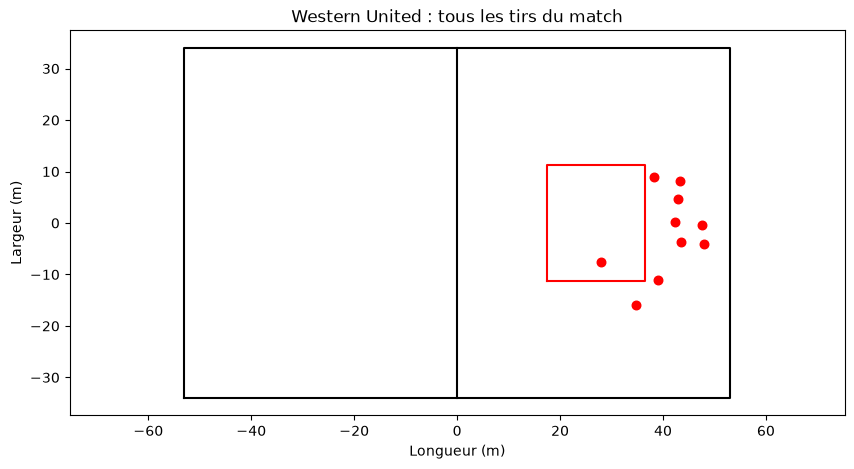

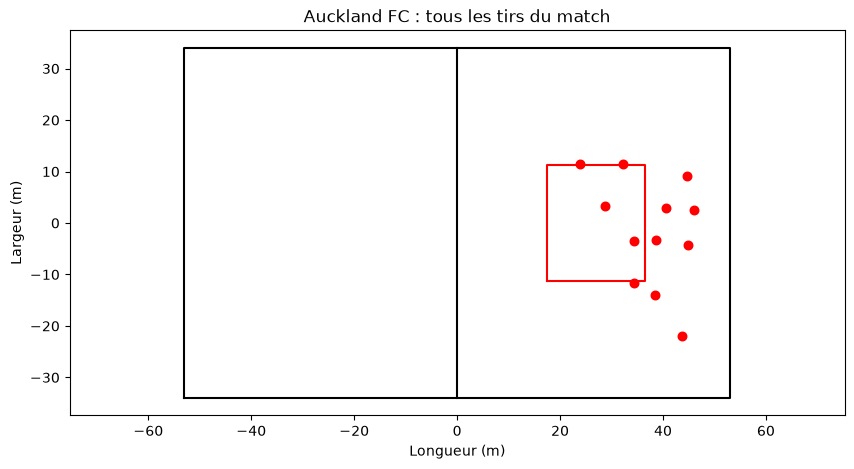

In [70]:
for nom in equipes:
    carte_actions(infos, tirs_match[nom],
                  nom + ' : tous les tirs du match', 'frappes')
    plt.axis('equal')


## 8. Cartes combinées : tirs et passes depuis la zone 14 associées à un tir

Comme dans le notebook 02, nous parcourons les équipes avec une boucle `for`, puis créons une figure par équipe avec `plt.figure()` et `tracer_terrain()`. La méthode `plt.scatter()` affiche les coordonnées des actions sur ce terrain : les tirs sont en rouge et les passes depuis la zone 14 liées à un tir en bleu. 

La fonction `passes_depuis_zone14()` sélectionne les passes dont le joueur se situe dans la zone 14 à la fin de sa possession. Nous conservons celles pour lesquelles `lead_to_shot` indique un lien avec un tir. Les coordonnées `x_end` et `y_end` situent le passeur au moment de la passe, pas le lieu de réception. L'indicateur ne permet pas d'associer chaque passe à un tir précis.

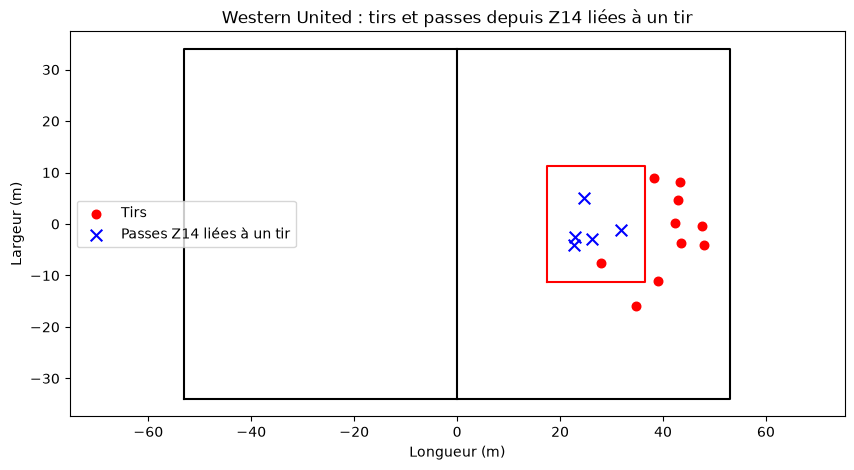

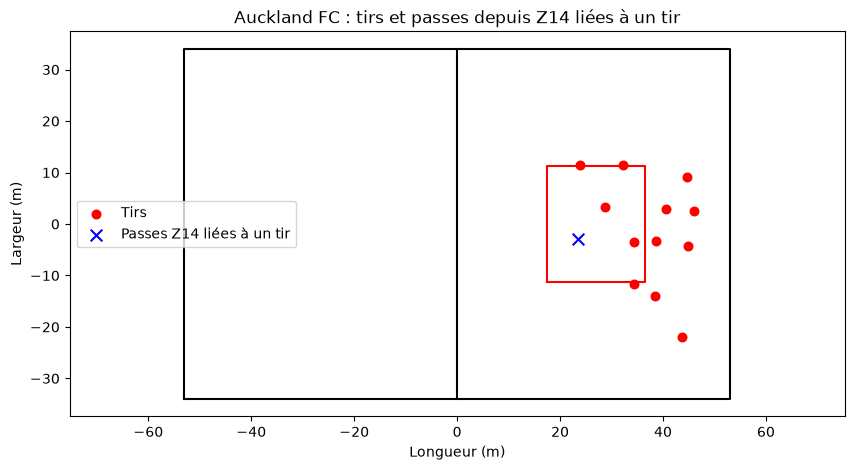

In [71]:
#On sélectionne les passes depuis Z14 liées à un tir pour chaque équipe.
passes_zone14_liees_tir = {}
for nom, identifiant in equipes.items():
    passes_z14 = passes_depuis_zone14(infos, evenements, identifiant)
    indicateur = passes_z14['lead_to_shot'].astype(str).str.lower()
    passes_zone14_liees_tir[nom] = passes_z14.loc[
        indicateur.isin(['true', '1', '1.0'])
    ].copy()

for nom in equipes:
    plt.figure(figsize=(10, 5))
    tracer_terrain(infos)

    tirs = tirs_match[nom]
    passes_tir = passes_zone14_liees_tir[nom]

    plt.scatter(tirs['x_end'], tirs['y_end'], color='red', s=38, label='Tirs')
    plt.scatter(passes_tir['x_end'], passes_tir['y_end'],
                color='blue', marker='x', s=70, label='Passes Z14 liées à un tir')

    plt.title(nom + ' : tirs et passes depuis Z14 liées à un tir')
    plt.axis('equal')
    plt.legend()

### Limite : Plusieurs passes peuvent être liées à un même tir.